In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rcParams
from matplotlib import rc
from matplotlib import colors
import seaborn as sb
from collections import Counter
import glob
import gseapy as gp

#sc.settings.set_figure_params(dpi = 160, color_map = 'RdPu', dpi_save = 300, format = 'pdf')
sc.settings.set_figure_params(dpi = 160, color_map = 'RdYlBu_r', dpi_save = 300, format = 'pdf')

plt.rcParams["figure.figsize"] = [6,6]

In [2]:
sb.set_palette('colorblind')

In [3]:
# set working directory
%cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/

/nfs/team205/cs42/HSC/HSC_new_to_transfer


In [4]:
from matplotlib import font_manager
font_manager.fontManager.addfont("csv/Helvetica.ttf")
print(font_manager.findfont("Helvetica"))
plt.rcParams["font.sans-serif"] = ["Helvetica"]
plt.rcParams["pdf.fonttype"] = 42

plt.rcParams['savefig.dpi'] = 300

plt.rcParams["axes.grid"] = False
plt.rcParams["pdf.fonttype"] = 42

/nfs/team205/cs42/HSC/HSC_new_to_transfer/csv/Helvetica.ttf


In [5]:
# figure directory
fig_path = 'figure/'
#fig_path = '/home/jovyan/mount/gdrive/HSC/chenqu_jhub/'
sc.settings.figdir = fig_path

# Load data

In [6]:
# load fetal stromal data from https://developmental.cellatlas.io/studies/fetal-immune
stroma = sc.read('reference_data_stroma/PAN.A01.v01.raw_count.20210429.STROMA.embedding.h5ad')

Only considering the two last: ['.embedding', '.h5ad'].
Only considering the two last: ['.embedding', '.h5ad'].


# RUNX2 DEGs 

## DEGs from Olli

In [7]:
deg = pd.read_csv('csv/ipsc_multiome_tf_degs_wilcoxon.csv', index_col=0)

In [8]:
deg = deg.loc[deg.index=='RUNX2',:]

In [9]:
deg = deg.loc[np.array(deg['pvals_adj']<0.05) & np.array(deg['logfoldchanges']>2),:]

In [10]:
runx2_list = list(deg['names'])

## Gene list scoring

In [11]:
runx2_list = [gene for gene in runx2_list if gene in stroma.var_names]
len(runx2_list)

226

In [12]:
sc.tl.score_genes(stroma, runx2_list, score_name = 'runx2')

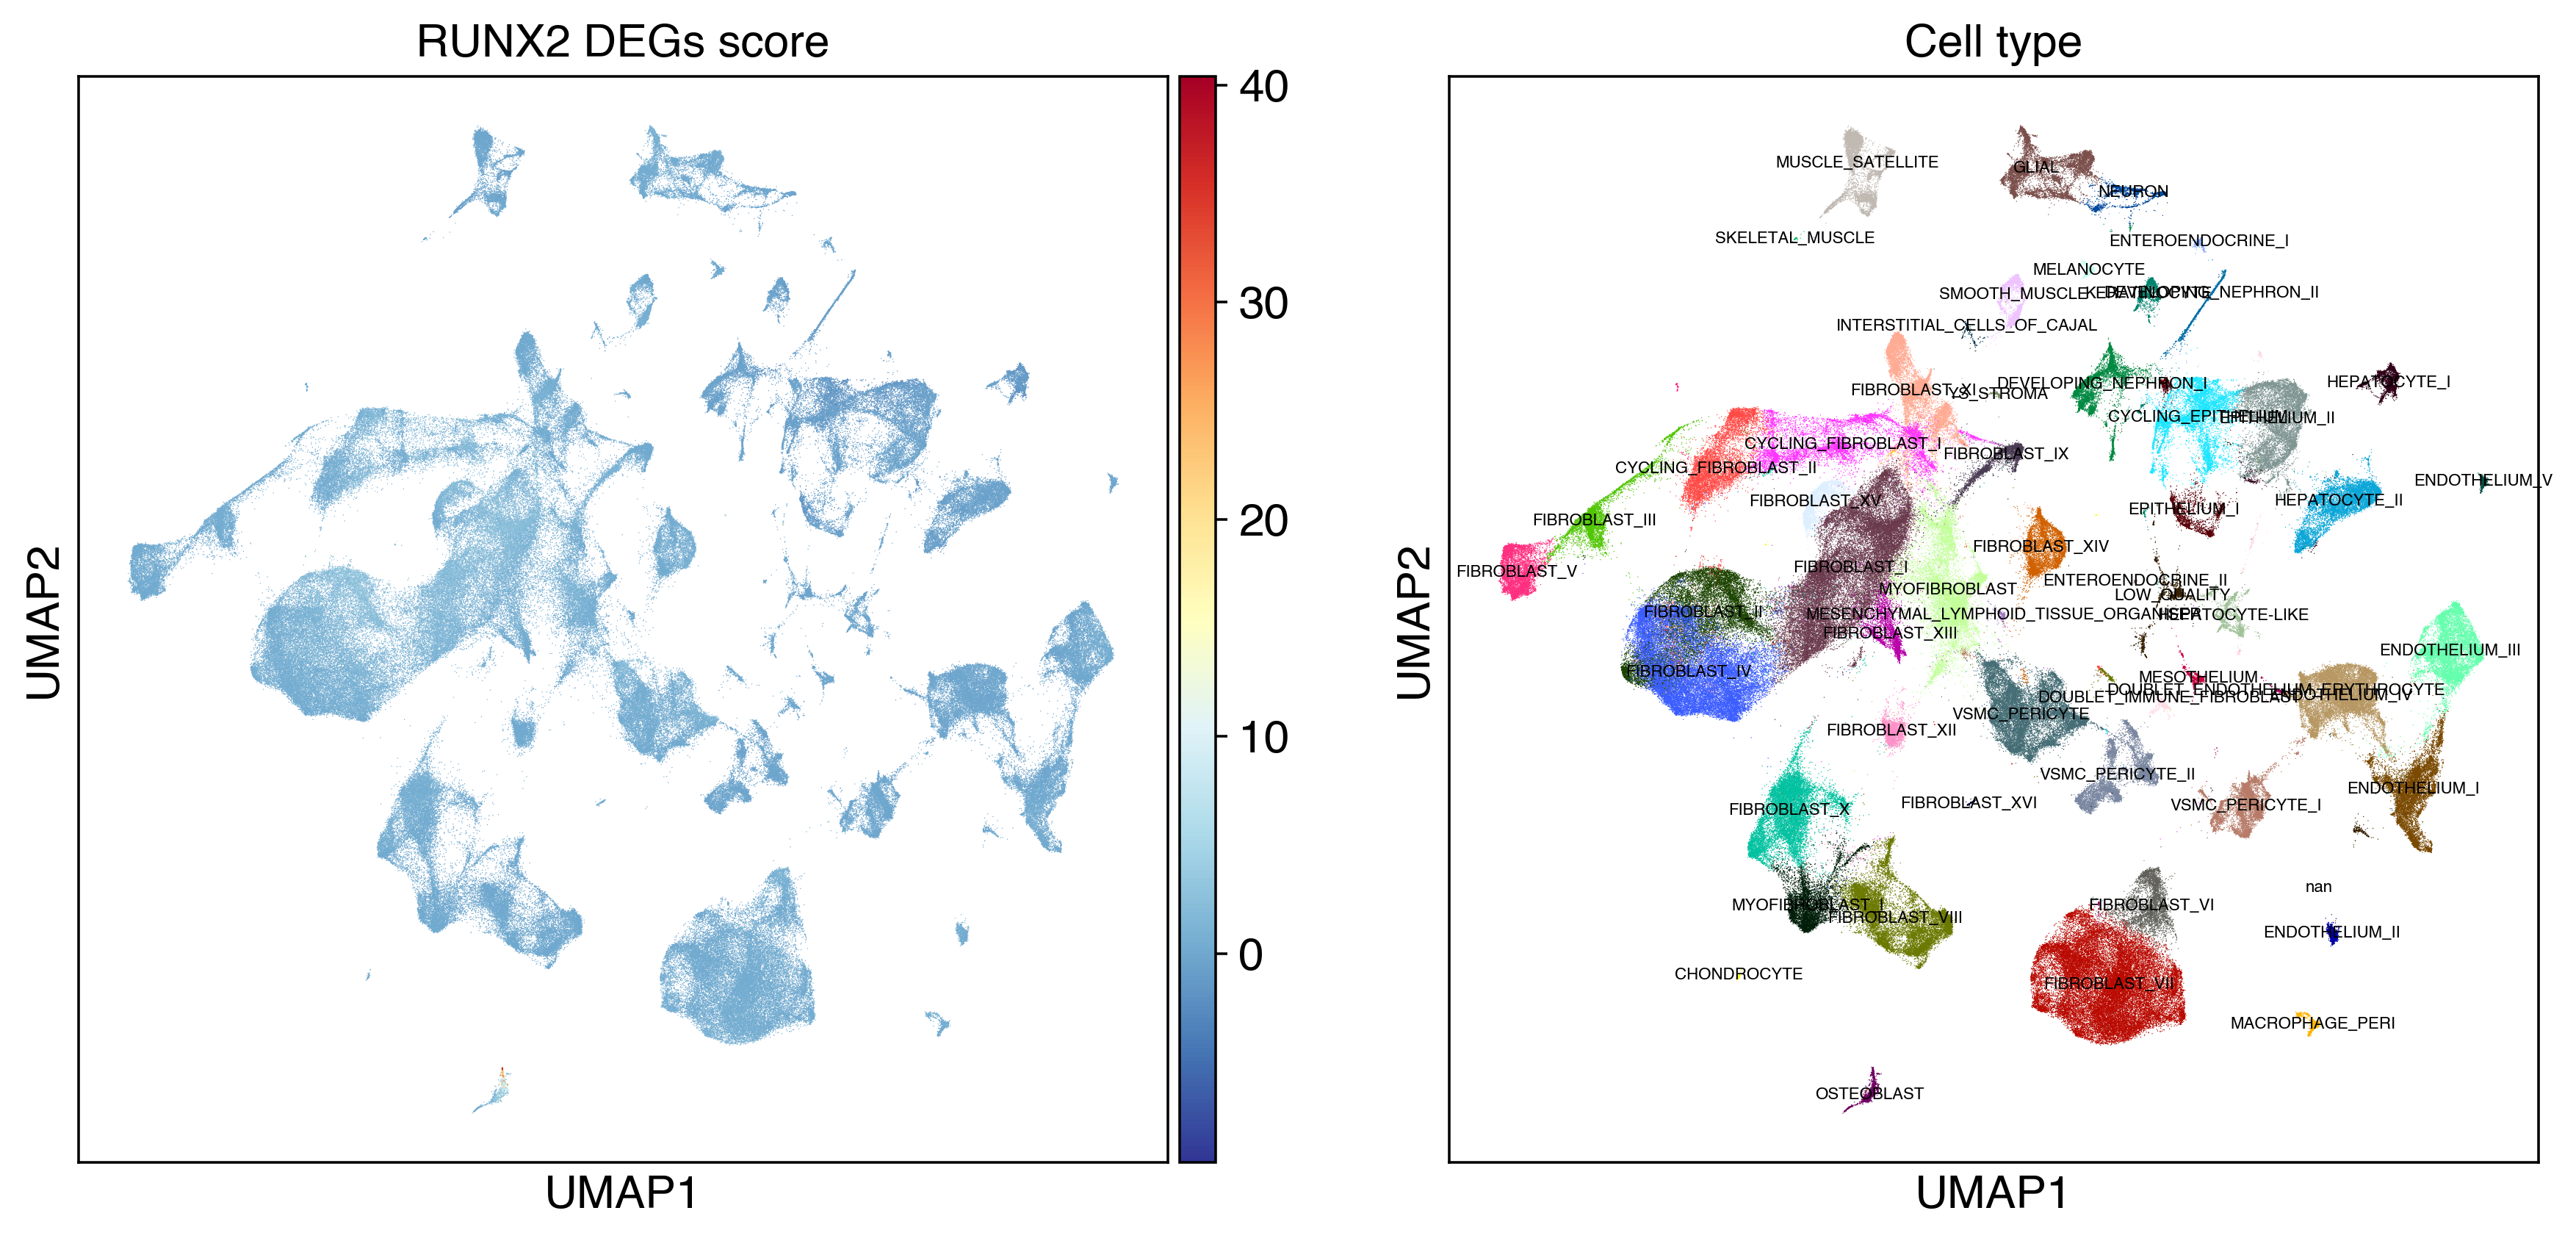

In [13]:
plt.rcParams["figure.figsize"] = [6,6]
sc.pl.umap(stroma, color=['runx2','anno_lvl_2_final_clean'], 
           title = ['RUNX2 DEGs score', 'Cell type'],
           legend_loc = 'on data', legend_fontsize=5, 
          save = 'runx2_score_umap.png')

/tmp/ipykernel_3507097/3392165687.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(group_key)[score_key]


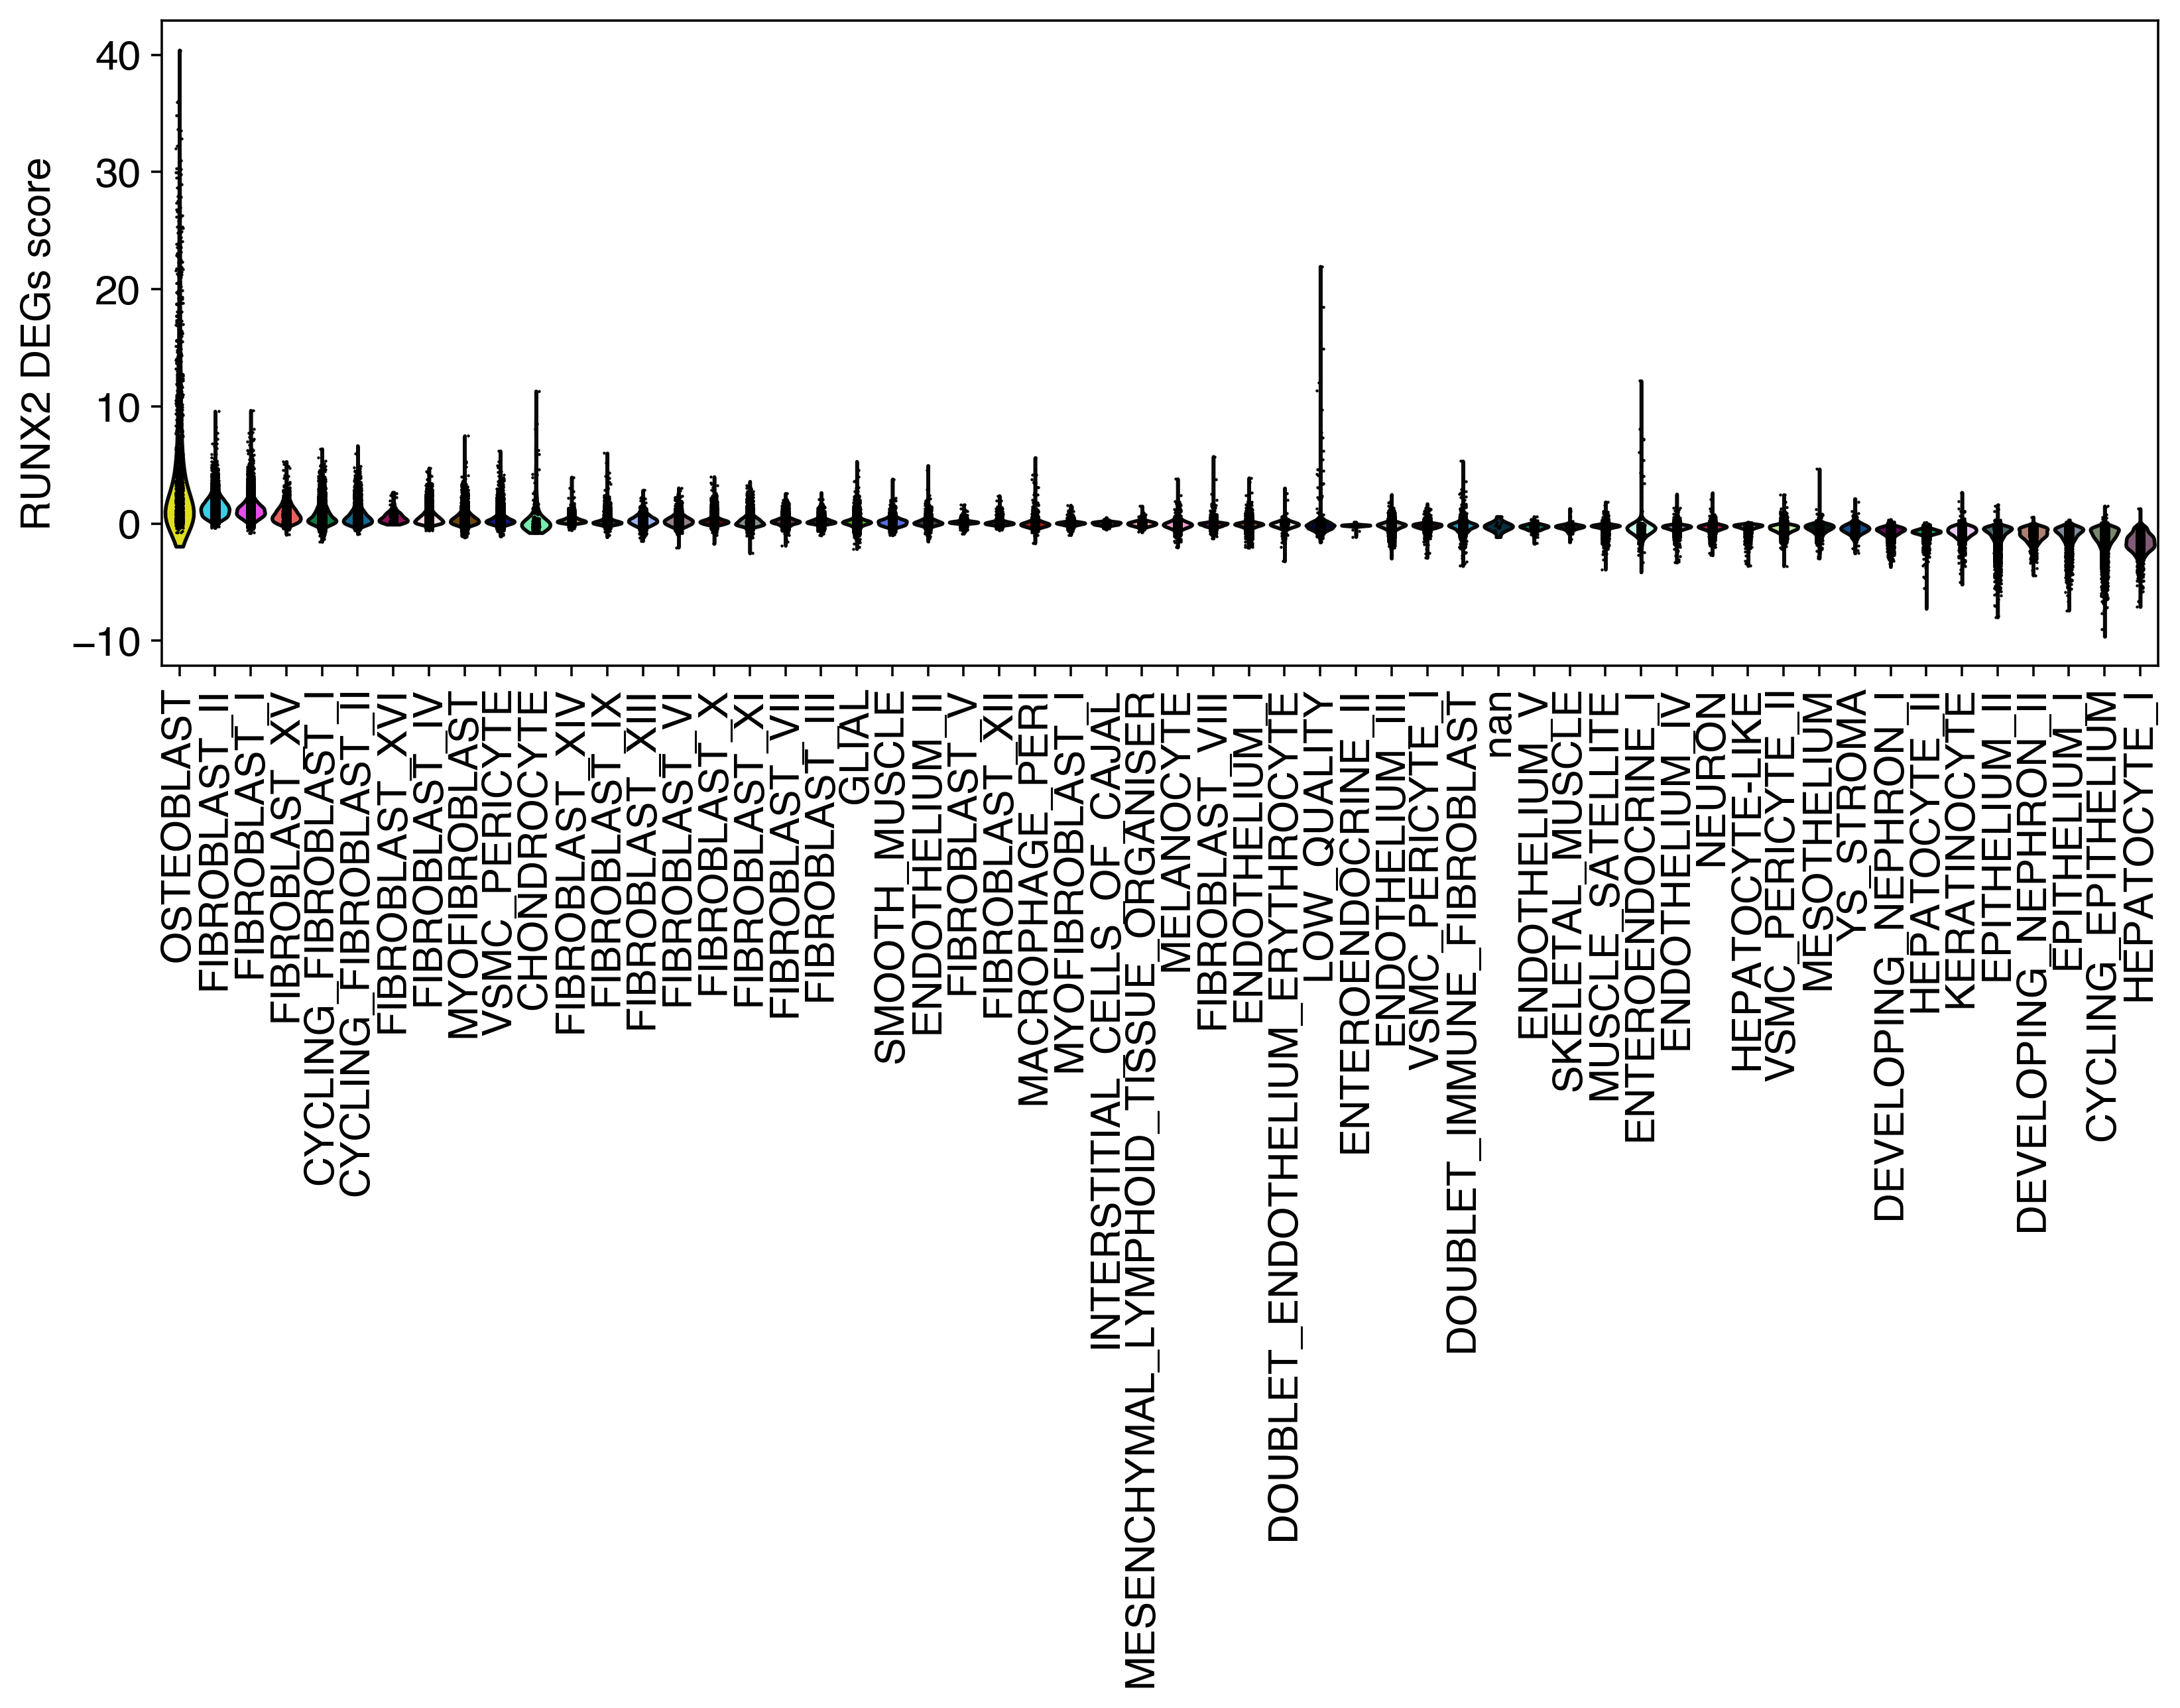

In [19]:
plt.rcParams["figure.figsize"] = [10,4]
score_key = "runx2"
group_key = "anno_lvl_2_final_clean"

# Compute mean runx2 score per group, highest to lowest
ordered_groups = (
    stroma.obs
    .groupby(group_key)[score_key]
    .mean()
    .sort_values(ascending=False)
    .index
)

# Apply this ordering to the annotation column
stroma.obs[group_key] = stroma.obs[group_key].cat.reorder_categories(list(ordered_groups))

# Plot
sc.pl.violin(
    stroma,
    keys=score_key,
    groupby=group_key,
    rotation=90,
    ylabel="RUNX2 DEGs score",
    save="runx2_score_violin.pdf"
)

Osteoblast has the highest scores

### Isolate osteoblast to investigate further

In [20]:
osteo = stroma[stroma.obs['anno_lvl_2_final_clean']=='OSTEOBLAST']

In [22]:
sc.pp.normalize_per_cell(osteo,counts_per_cell_after=1e4)

/tmp/ipykernel_3507097/878794542.py:1: FutureWarning: Use sc.pp.normalize_total instead
  sc.pp.normalize_per_cell(osteo,counts_per_cell_after=1e4)
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:591: FutureWarning: Use sc.pp.normalize_total instead
  normalize_per_cell(


In [23]:
sc.pp.log1p(osteo)

In [24]:
sc.pp.neighbors(osteo, use_rep = 'X_scvi', random_state = 1712)
sc.tl.umap(osteo, random_state = 1712)

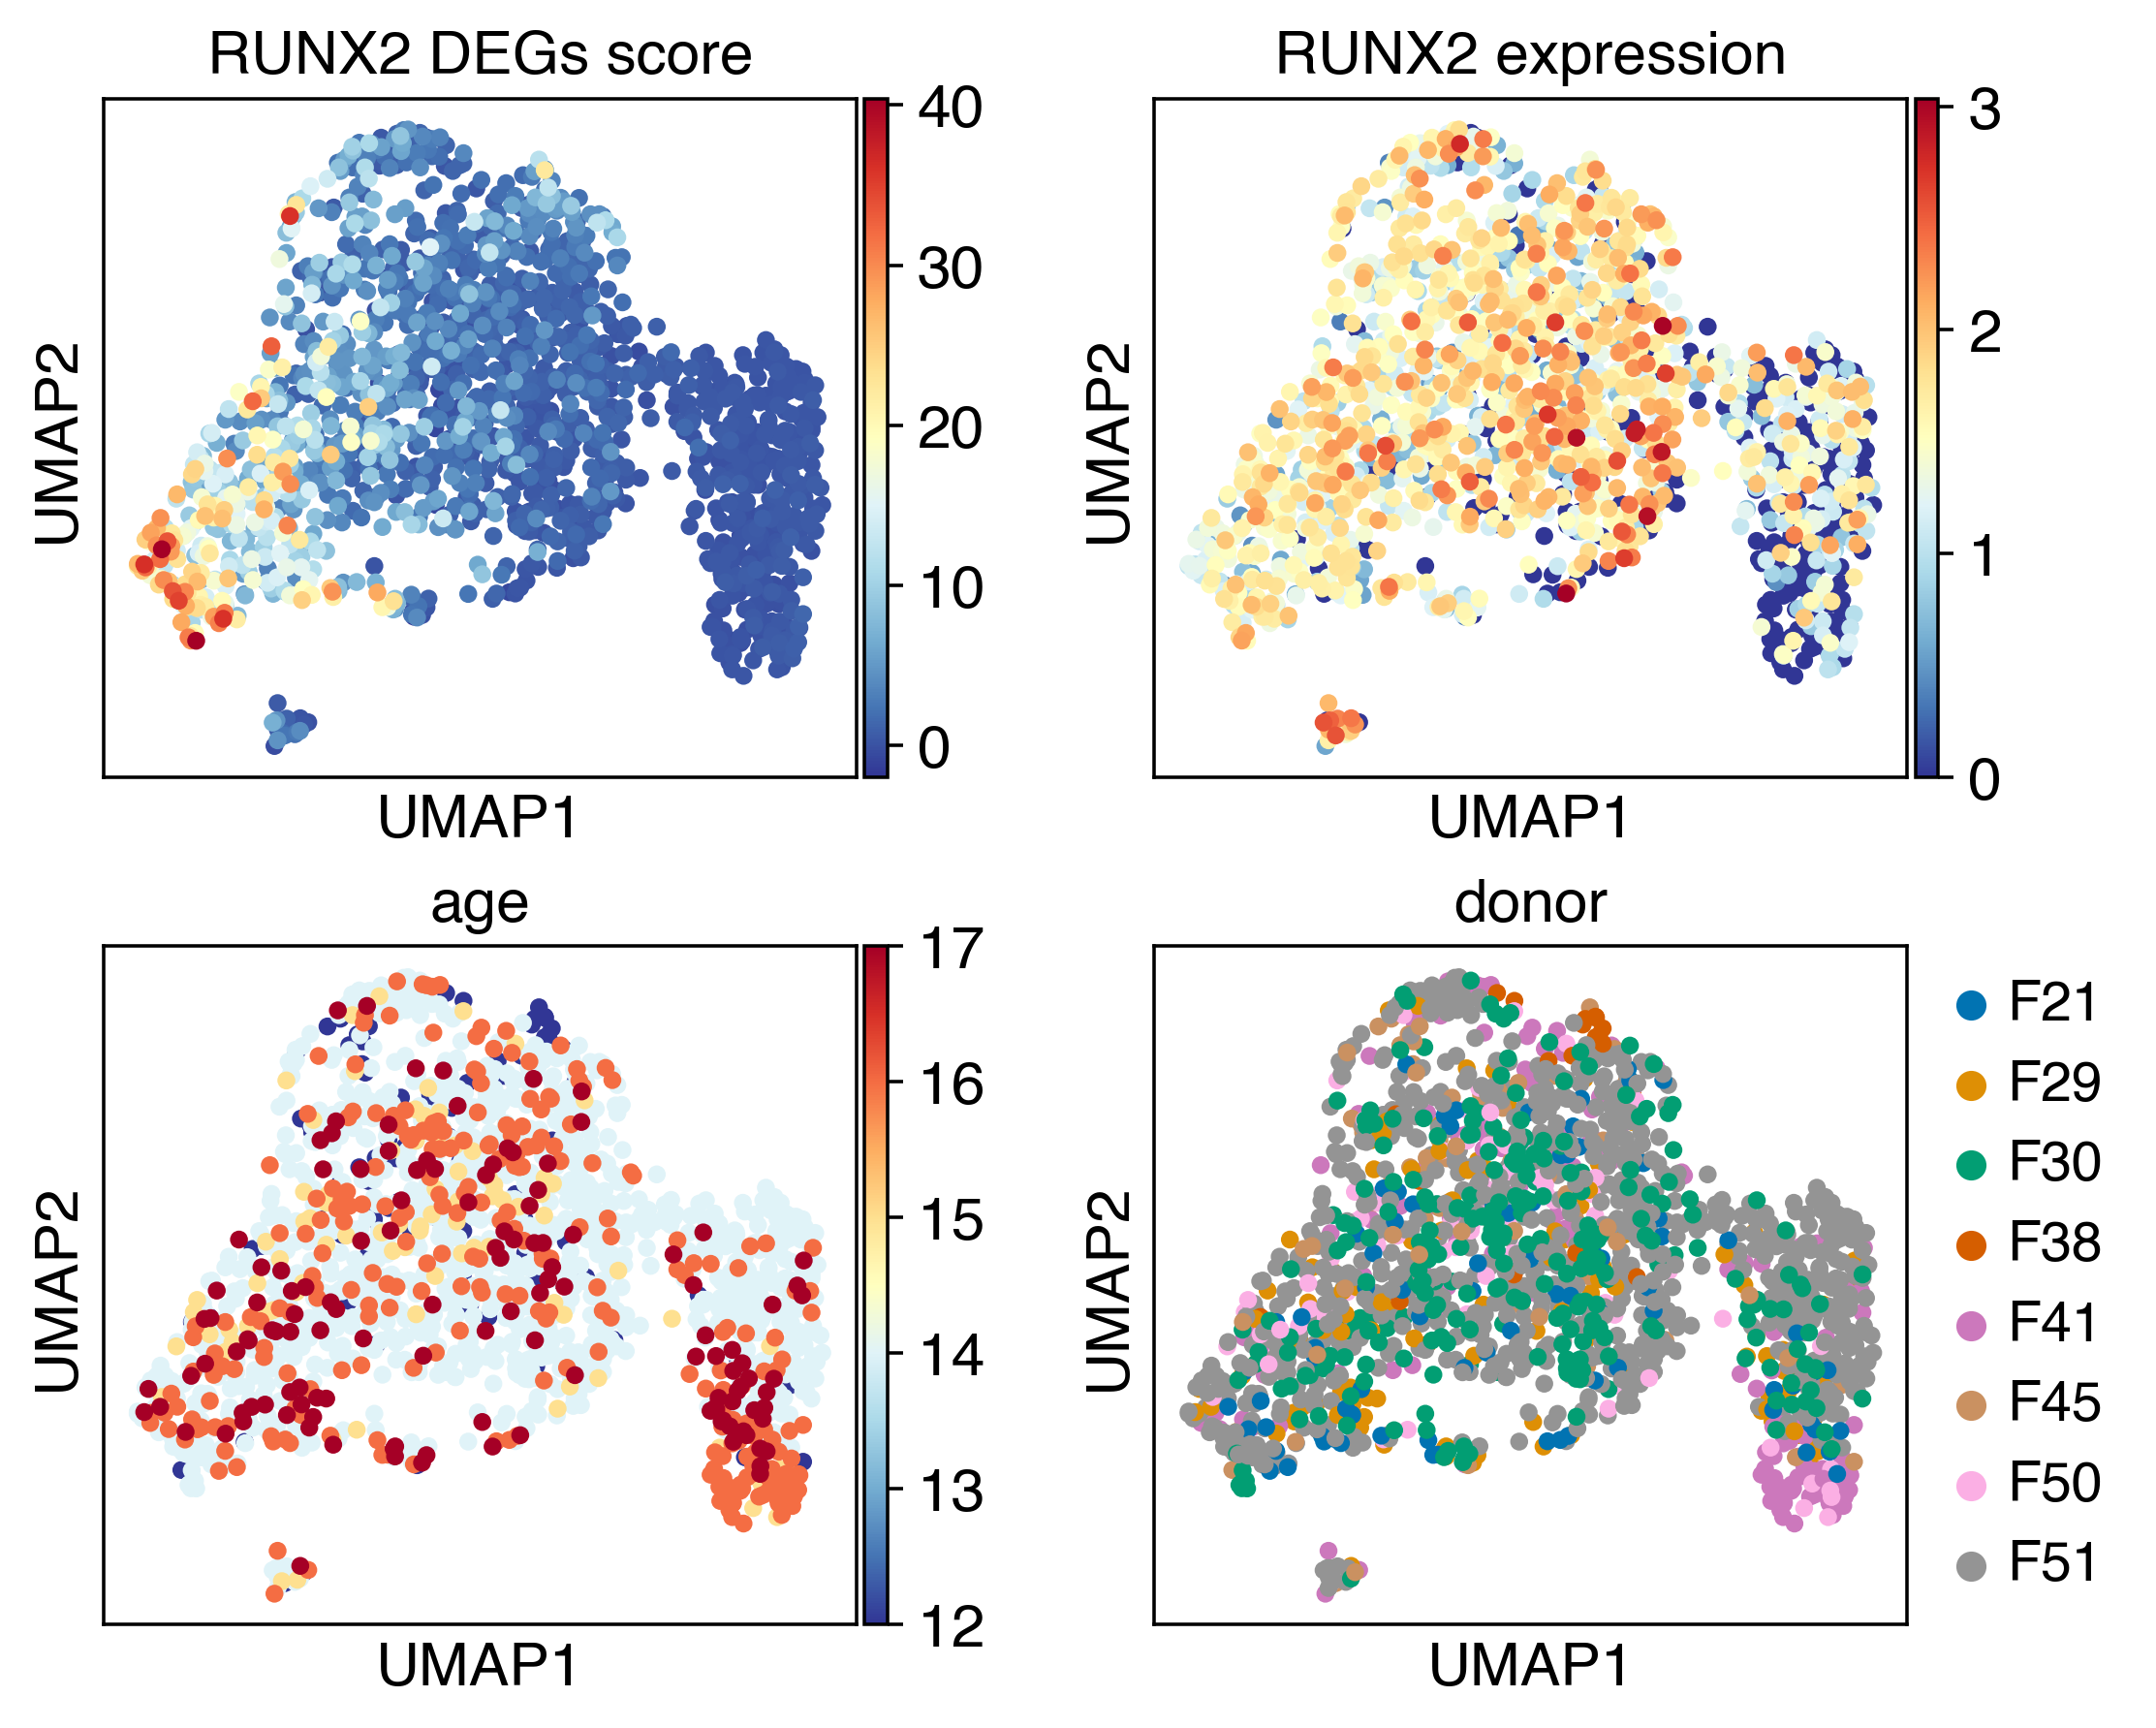

In [25]:
plt.rcParams["figure.figsize"] = [3,3]
sc.pl.umap(osteo, color=['runx2','RUNX2','age','donor'], 
           title = ['RUNX2 DEGs score', 'RUNX2 expression','age','donor'],
           ncols=2)

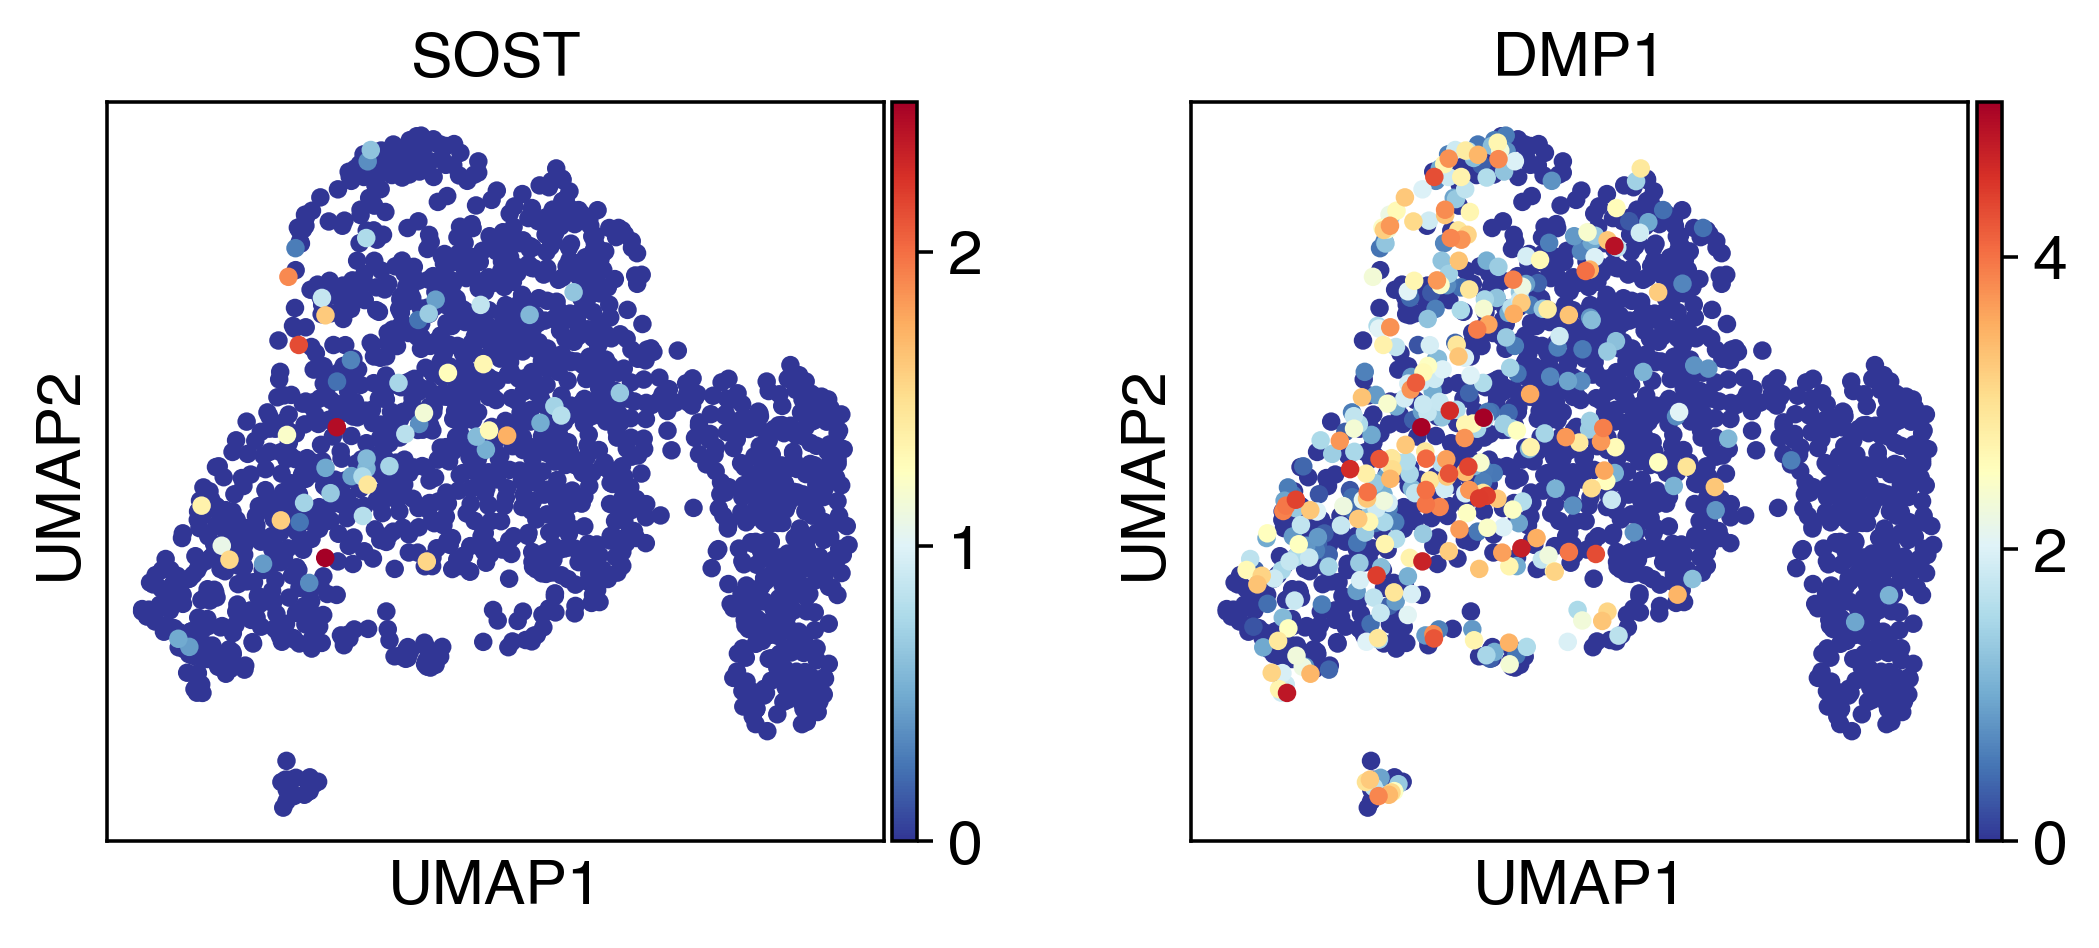

In [26]:
plt.rcParams["figure.figsize"] = [3,3]
sc.pl.umap(osteo, color=['SOST','DMP1',], 
           ncols=4)

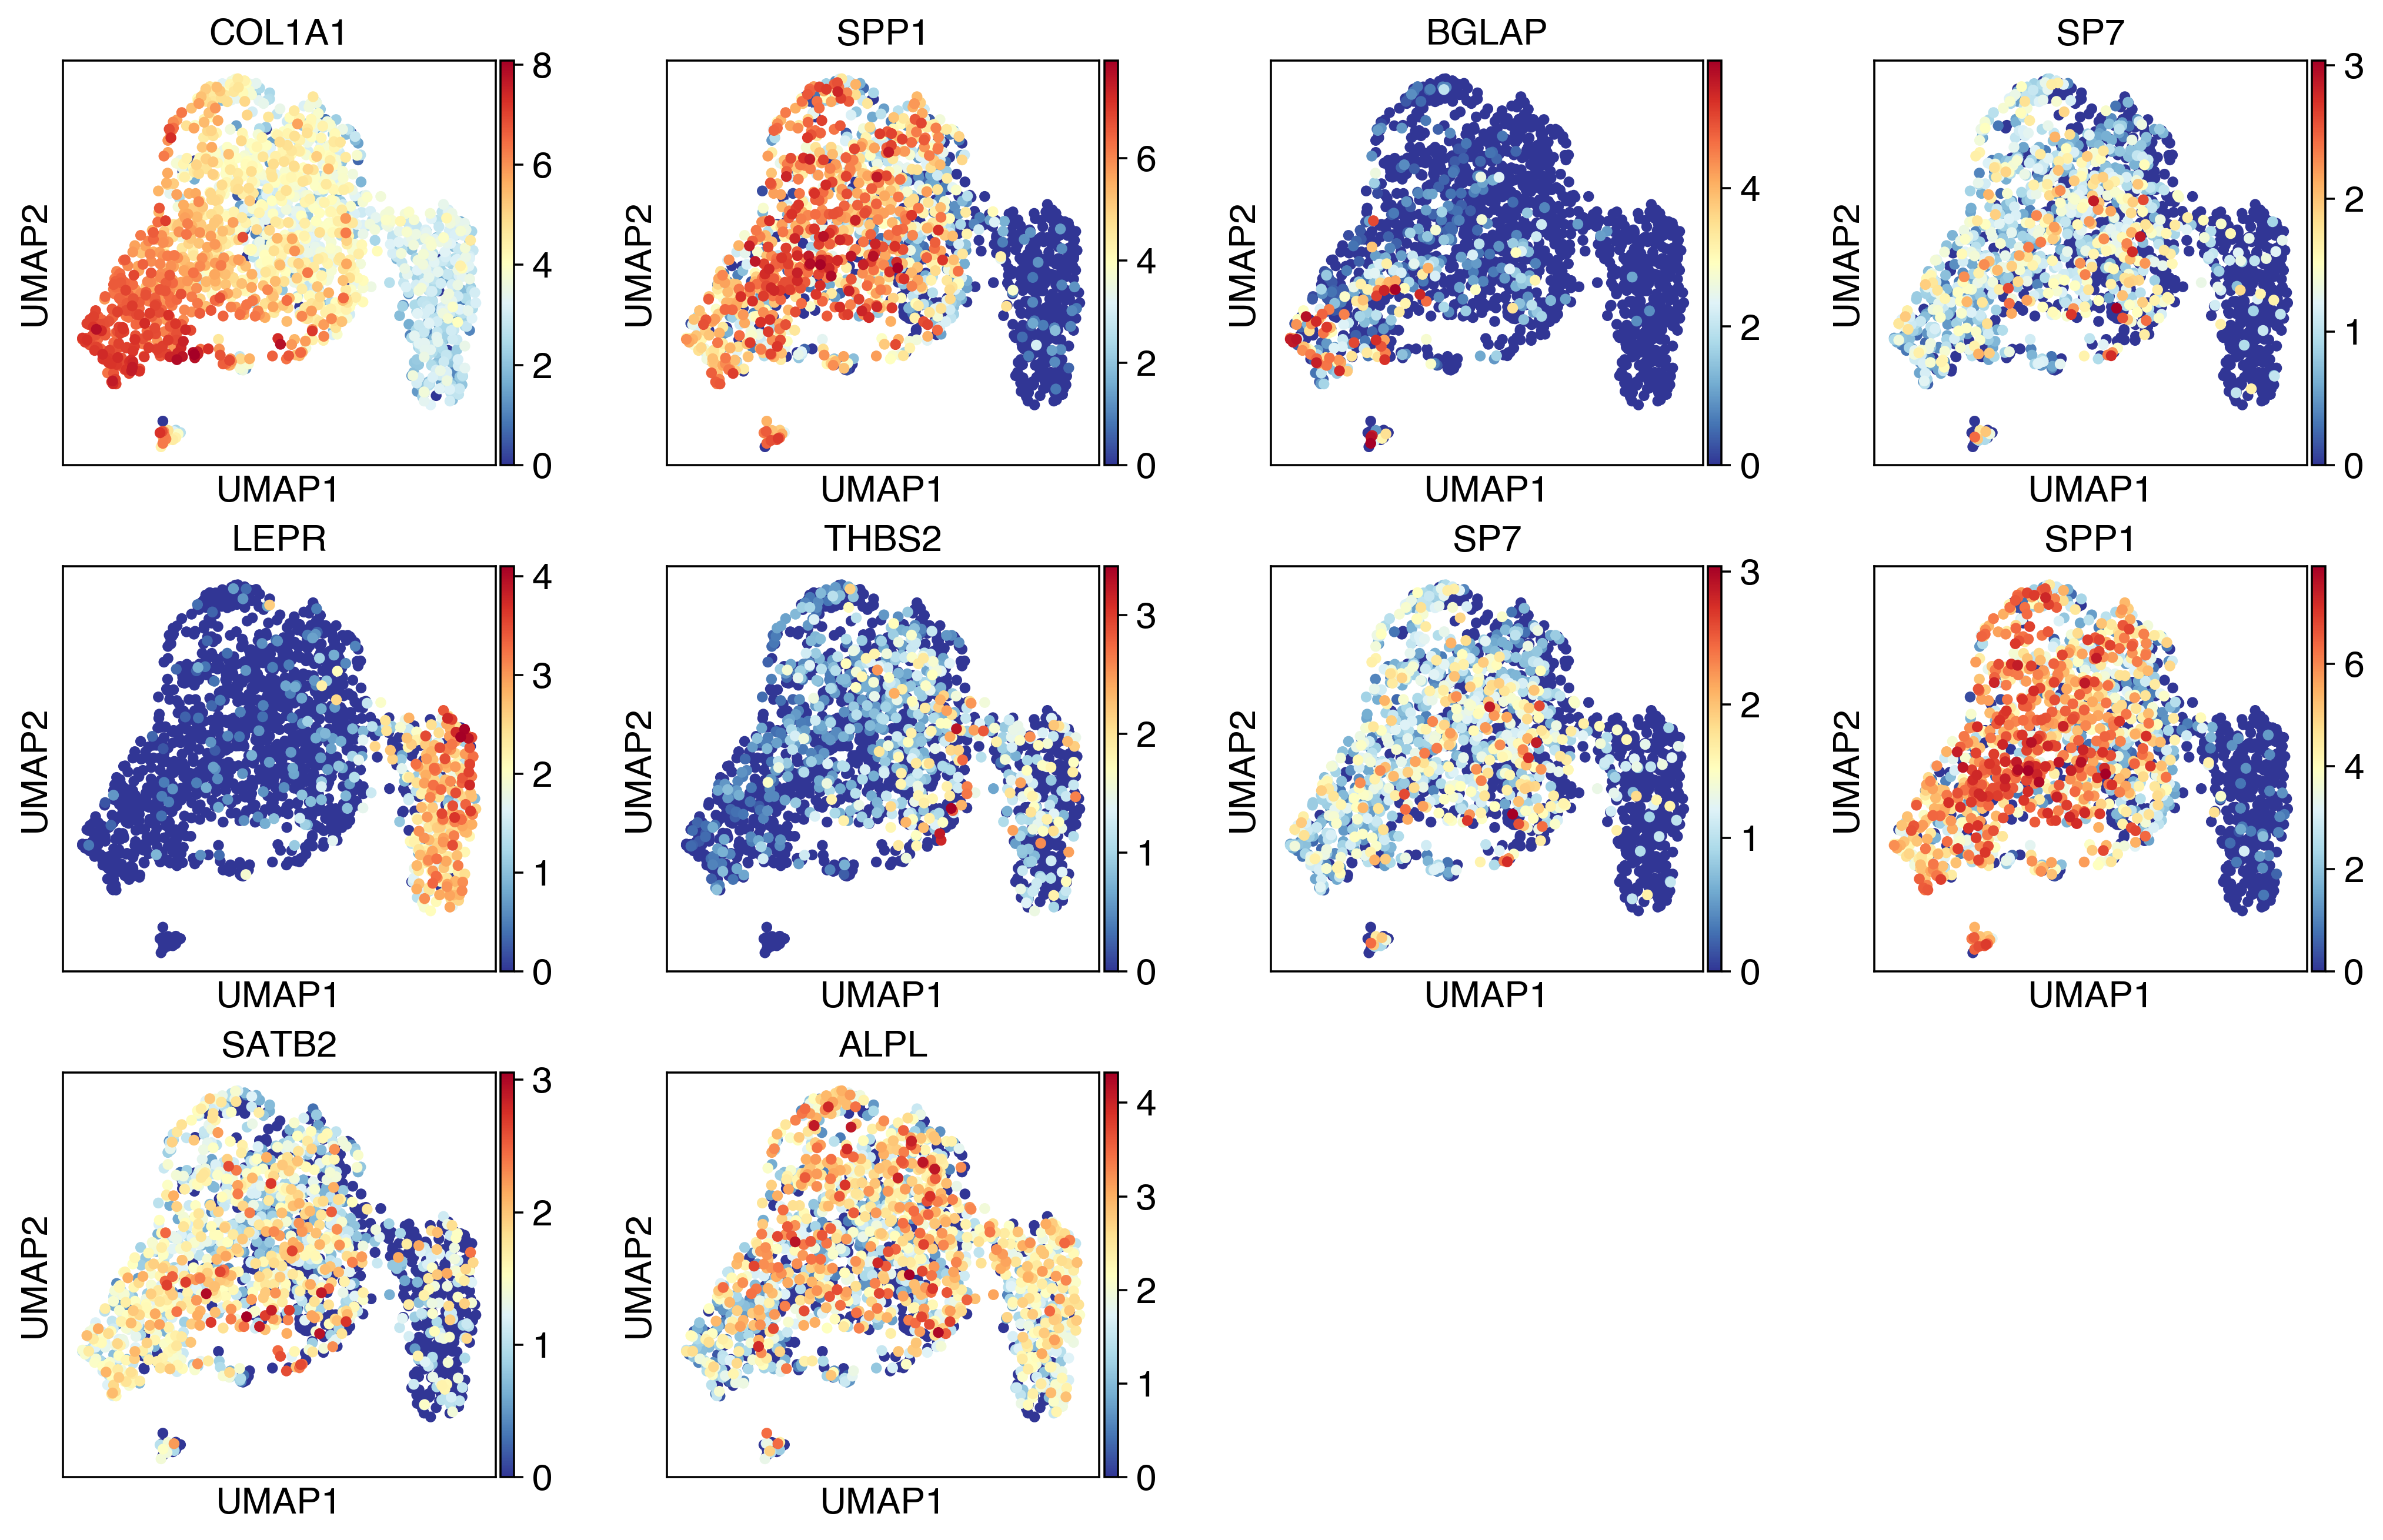

In [27]:
plt.rcParams["figure.figsize"] = [3,3]
sc.pl.umap(osteo, color=['COL1A1','SPP1','BGLAP','SP7',
                        'LEPR','THBS2','SP7','SPP1','SATB2','ALPL',], 
           ncols=4)

/tmp/ipykernel_3489862/3359938687.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(osteo, resolution = 0.5)


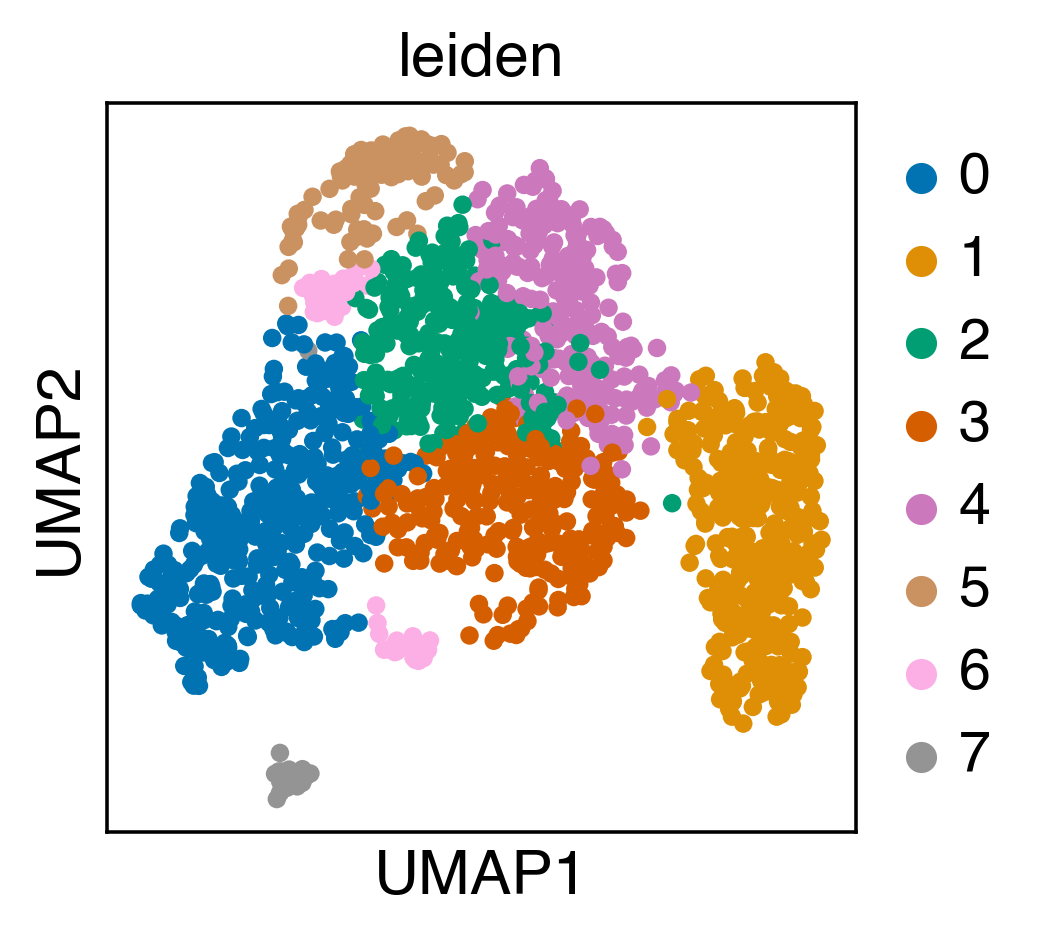

In [54]:
sc.tl.leiden(osteo, resolution = 0.5)
sc.pl.umap(osteo, color='leiden')

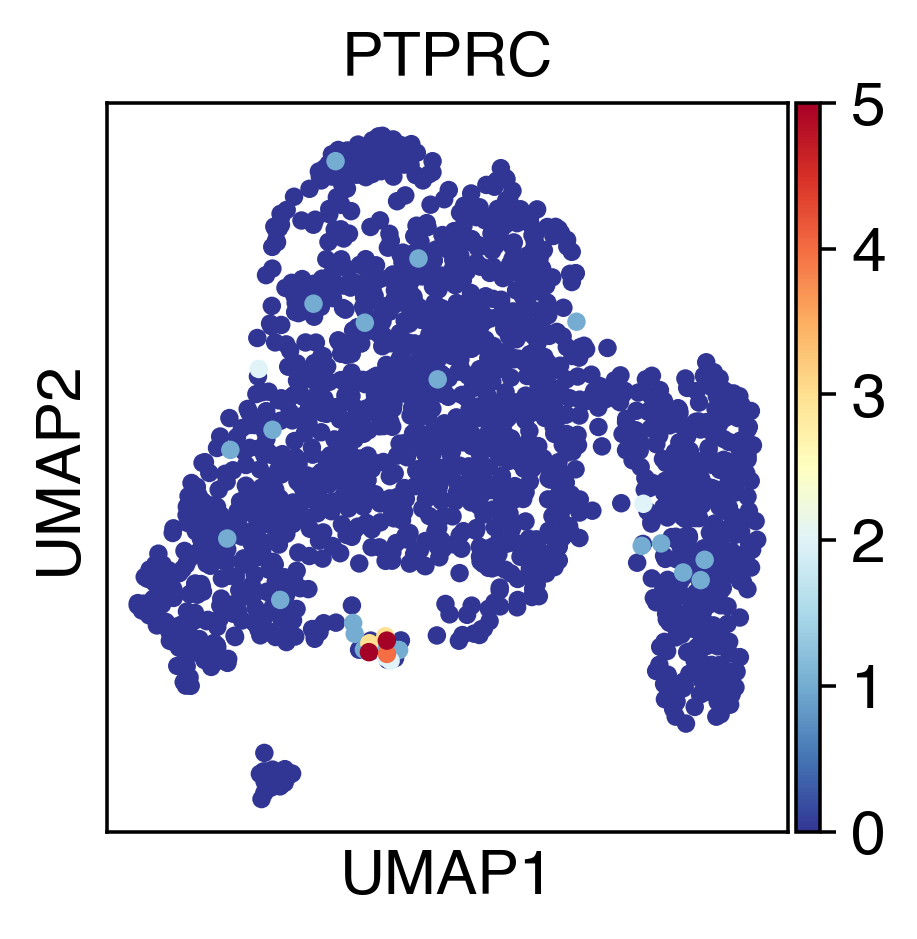

In [56]:
sc.pl.umap(osteo, color='PTPRC')

In [57]:
# dge by wilcoxon
sc.tl.rank_genes_groups(osteo, "leiden", method="wilcoxon", use_raw=False)

/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:479: RuntimeWarning: overflow encountered in expm1
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (


In [60]:
# compile dge results
result = osteo.uns["rank_genes_groups"]
groups = ['0']
df = pd.DataFrame(
    {
        f"{group}_{key[:1]}": result[key][group]
        for group in groups
        for key in ["names", "pvals_adj",'logfoldchanges']
    }
)

In [72]:
# choose up dges
select = np.array(df['0_p']< 0.05) & np.array(df['0_l']>2)
degs_up = df.loc[select,'0_n']

enr_up = gp.enrichr(degs_up,
                        gene_sets='MSigDB_Hallmark_2020',
                        outdir=None)
# enrichr result
enr_up.res2d.loc[0:10,:]

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,MSigDB_Hallmark_2020,Oxidative Phosphorylation,69/200,1.138934e-39,5.694672e-38,0,0,10.772316,965.961358,GPI;COX7B;SLC25A3;COX4I1;COX6A1;COX7C;PDK4;TIM...
1,MSigDB_Hallmark_2020,Myc Targets V1,46/200,1.088344e-18,2.720861e-17,0,0,5.953186,246.234945,SLC25A3;HSP90AB1;RPL34;RPLP0;COX5A;RPL6;HSPD1;...
2,MSigDB_Hallmark_2020,Epithelial Mesenchymal Transition,37/200,3.379052e-12,5.631754e-11,0,0,4.479266,118.312770,LRRC15;COPA;SPARC;PCOLCE2;PLOD2;TNFRSF11B;THBS...
3,MSigDB_Hallmark_2020,Protein Secretion,24/96,3.197219e-11,3.996524e-10,0,0,6.520661,157.579306,RAB2A;TPD52;COPB2;CD63;ARF1;TMED10;COPB1;BNIP3...
4,MSigDB_Hallmark_2020,mTORC1 Signaling,35/200,6.582438e-11,6.582438e-10,0,0,4.176594,97.916187,GPI;FKBP2;SHMT2;RPN1;USO1;PLOD2;ENO1;ATP5MC1;H...
5,MSigDB_Hallmark_2020,Unfolded Protein Response,25/113,2.145425e-10,1.787854e-09,0,0,5.558428,123.744581,EIF4A2;FKBP14;HERPUD1;RPS14;SERP1;EIF4EBP1;SSR...
6,MSigDB_Hallmark_2020,Hypoxia,26/200,6.868394e-06,4.292746e-05,0,0,2.913329,34.635346,GPI;SRPX;LXN;BTG1;SDC2;HDLBP;ENO1;MT2A;LDHA;PR...
7,MSigDB_Hallmark_2020,Adipogenesis,26/200,6.868394e-06,4.292746e-05,0,0,2.913329,34.635346,COX7B;CD151;NDUFB7;AK2;UQCR11;UQCR10;COX6A1;ME...
8,MSigDB_Hallmark_2020,Glycolysis,25/200,2.030059e-05,1.085203e-04,0,0,2.782243,30.061744,COPB2;CHPF;SDC2;HDLBP;PLOD2;ENO1;TXN;GMPPB;LDH...
9,MSigDB_Hallmark_2020,Reactive Oxygen Species Pathway,11/49,2.170405e-05,1.085203e-04,0,0,5.597672,60.107862,PRDX2;PRDX4;NDUFA6;GPX4;SELENOS;NDUFB4;PRDX1;T...
